# Computational Imaging - Group I Project: Superresolution
**Dataset**: LSUN Church (256x256)
**Methods**: UNet (End-to-end), Total Variation (Variational), DiffPIR (Generative)


## 1. Setup and Installs
Install required packages. Diffusers is needed for DiffPIR.


In [99]:
!pip install -q diffusers transformers accelerate


In [100]:
import os
import time
import math
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import json

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import ReduceLROnPlateau
from diffusers import UNet2DModel
from skimage.metrics import peak_signal_noise_ratio as psnr_metric
from skimage.metrics import structural_similarity as ssim_metric

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"Number of GPUs: {torch.cuda.device_count()}")


Using device: cuda
Number of GPUs: 2


In [101]:
## 2. Normalization and Metrics

class ImageNormalizer:
    def __init__(self, mode='0_1'):
        self.mode = mode

    def normalize(self, tensor: torch.Tensor) -> torch.Tensor:
        if tensor.max() > 1.0:
            tensor = tensor.float() / 255.0
        if self.mode == '0_1':
            return tensor
        elif self.mode == 'neg1_1':
            return (tensor * 2.0) - 1.0
        else:
            raise ValueError("Mode not supported")

    def denormalize(self, tensor: torch.Tensor) -> torch.Tensor:
        if self.mode == '0_1':
            return torch.clamp(tensor, 0.0, 1.0)
        elif self.mode == 'neg1_1':
            return torch.clamp((tensor + 1.0) / 2.0, 0.0, 1.0)

default_normalizer = ImageNormalizer(mode='0_1')

def compute_psnr(pred, target):
    pred_np = pred.detach().cpu().permute(1, 2, 0).numpy() if pred.ndim == 3 else pred.detach().cpu().squeeze(0).permute(1, 2, 0).numpy()
    target_np = target.detach().cpu().permute(1, 2, 0).numpy() if target.ndim == 3 else target.detach().cpu().squeeze(0).permute(1, 2, 0).numpy()
    return float(psnr_metric(target_np, pred_np, data_range=1.0))

def compute_ssim(pred, target):
    pred_np = pred.detach().cpu().permute(1, 2, 0).numpy() if pred.ndim == 3 else pred.detach().cpu().squeeze(0).permute(1, 2, 0).numpy()
    target_np = target.detach().cpu().permute(1, 2, 0).numpy() if target.ndim == 3 else target.detach().cpu().squeeze(0).permute(1, 2, 0).numpy()
    return float(ssim_metric(target_np, pred_np, data_range=1.0, channel_axis=2))


In [102]:
## 3. Degradation Operator and Dataset

class DegradationOperator:
    def __init__(self, sr_factor=2, noise_std=0.005, seed=42, device='cpu'):
        self.sr_factor = sr_factor
        self.noise_std = noise_std
        self.seed = seed
        self.device = device
        
    def __call__(self, img_tensor):
        if isinstance(img_tensor, Image.Image):
            img_tensor = torch.from_numpy(np.array(img_tensor)).float()
            if len(img_tensor.shape) == 3: img_tensor = img_tensor.permute(2, 0, 1)
        img_tensor = default_normalizer.normalize(img_tensor).float().to(self.device)
        if len(img_tensor.shape) == 3: img_tensor = img_tensor.unsqueeze(0)
        
        degraded = self._downsample(img_tensor)
        degraded = self._add_noise(degraded)
        return degraded.squeeze(0)
    
    def _downsample(self, x):
        kernel_size = self.sr_factor * 2 + 1
        sigma = self.sr_factor / np.sqrt(8 * np.log(2))
        kernel = self._create_gaussian_kernel(kernel_size, sigma).to(self.device)
        B, C, H, W = x.shape
        blurred = torch.zeros_like(x)
        for i in range(C):
            blurred[:, i:i+1, :, :] = F.conv2d(x[:, i:i+1, :, :], kernel, padding=kernel_size // 2)
        return F.interpolate(blurred, scale_factor=1/self.sr_factor, mode='bilinear', align_corners=False)
    
    def _add_noise(self, x):
        torch.manual_seed(self.seed)
        return torch.clamp(x + torch.randn_like(x) * self.noise_std, 0.0, 1.0)
    
    @staticmethod
    def _create_gaussian_kernel(kernel_size, sigma):
        x = torch.arange(kernel_size).float() - (kernel_size - 1) / 2.0
        gauss = torch.exp(-(x ** 2) / (2 * sigma ** 2))
        kernel_1d = gauss / gauss.sum()
        kernel_2d = kernel_1d.unsqueeze(-1) @ kernel_1d.unsqueeze(0)
        return kernel_2d.unsqueeze(0).unsqueeze(0)

class SRDataset(Dataset):
    def __init__(self, image_dir, sr_factor=2, noise_std=0.005, max_images=None):
        self.files = sorted(Path(image_dir).glob("*.png")) + sorted(Path(image_dir).glob("*.jpg"))
        if max_images: self.files = self.files[:max_images]
        self.degrader = DegradationOperator(sr_factor=sr_factor, noise_std=noise_std)

    def __len__(self): return len(self.files)

    def __getitem__(self, idx):
        img = Image.open(self.files[idx]).convert('RGB')
        # FORZIAMO IL RESIZE A 256x256 INDIPENDENTEMENTE DAL DATASET SCELTO!
        if img.size != (256, 256):
            img = img.resize((256, 256), Image.Resampling.BICUBIC)
            
        gt = default_normalizer.normalize(torch.from_numpy(np.array(img)).float().permute(2, 0, 1))
        self.degrader.seed = 42 + idx
        degraded = self.degrader(img)
        degraded_up = F.interpolate(degraded.unsqueeze(0), size=(256, 256), mode='bicubic', align_corners=False).squeeze(0)
        return torch.clamp(degraded_up, 0.0, 1.0), gt

# KAGGLE CONFIGURATION
# Set the path to your dataset correctly. Es: "/kaggle/input/lsun-church-data/kaggle/working/lsun_church"
KAGGLE_DATASET_PATH = "/kaggle/input/datasets/mattiafurini/lsun-church-256x256"


In [103]:
## 4. End-to-End: UNet Architecture & Training Loop

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.LeakyReLU(0.2, inplace=True),
        )
    def forward(self, x): return self.block(x)

class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=3, features=[64, 128, 256, 512]):
        super().__init__()
        self.encoder_blocks = nn.ModuleList()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        prev = in_channels
        for feat in features:
            self.encoder_blocks.append(DoubleConv(prev, feat))
            prev = feat
        self.bottleneck = DoubleConv(features[-1], features[-1] * 2)
        self.upconvs = nn.ModuleList()
        self.decoder_blocks = nn.ModuleList()
        prev = features[-1] * 2
        for feat in reversed(features):
            self.upconvs.append(nn.ConvTranspose2d(prev, feat, kernel_size=2, stride=2))
            self.decoder_blocks.append(DoubleConv(feat * 2, feat))
            prev = feat
        self.final_conv = nn.Conv2d(features[0], out_channels, kernel_size=1)

    def forward(self, x):
        skips = []
        for enc in self.encoder_blocks:
            x = enc(x)
            skips.append(x)
            x = self.pool(x)
        x = self.bottleneck(x)
        skips = skips[::-1]
        for upconv, dec, skip in zip(self.upconvs, self.decoder_blocks, skips):
            x = upconv(x)
            if x.shape != skip.shape:
                x = F.pad(x, [0, skip.shape[3]-x.shape[3], 0, skip.shape[2]-x.shape[2]])
            x = torch.cat([skip, x], dim=1)
            x = dec(x)
        return torch.sigmoid(self.final_conv(x))

def train_one_epoch(model, dataloader, optimizer, criterion, device):
    model.train()
    total_loss = 0.0
    for inputs, targets in dataloader:
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(dataloader)

@torch.no_grad()
def validate(model, dataloader, criterion, device):
    model.eval()
    total_loss, psnr_vals, ssim_vals = 0.0, [], []
    for inputs, targets in dataloader:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = model(inputs)
        total_loss += criterion(outputs, targets).item()
        for i in range(outputs.shape[0]):
            psnr_vals.append(compute_psnr(outputs[i], targets[i]))
            ssim_vals.append(compute_ssim(outputs[i], targets[i]))
    return total_loss / len(dataloader), np.mean(psnr_vals), np.mean(ssim_vals)


In [104]:
## 5. Variational: Total Variation (TV)

class TVSuperResolution:
    def __init__(self, sr_factor=2, noise_std=0.005, lambda_tv=0.01, n_iter=200, step_size=0.005, device='cpu'):
        self.sr_factor, self.lambda_tv, self.n_iter = sr_factor, lambda_tv, n_iter
        self.step_size, self.device = step_size, device
        k_size = sr_factor * 2 + 1
        self.kernel = DegradationOperator._create_gaussian_kernel(k_size, sr_factor/np.sqrt(8*np.log(2))).to(device)
        self.padding = k_size // 2

    def solve(self, y):
        C, H_lr, W_lr = y.shape[1] if y.ndim==4 else y.shape[0], y.shape[-2], y.shape[-1]
        H_hr, W_hr = H_lr * self.sr_factor, W_lr * self.sr_factor
        if y.ndim==3: y = y.unsqueeze(0)
        x = torch.clamp(F.interpolate(y, size=(H_hr, W_hr), mode='bicubic', align_corners=False), 0, 1)
        z, t = x.clone(), 1.0
        
        for _ in range(self.n_iter):
            x_old = x.clone()
            Hz = F.interpolate(torch.cat([F.conv2d(z[:, c:c+1], self.kernel, padding=self.padding) for c in range(C)], 1), scale_factor=1/self.sr_factor, mode='bilinear', align_corners=False)
            res = Hz - y
            up = F.interpolate(res, size=(H_hr, W_hr), mode='bilinear', align_corners=False)
            grad_data = torch.cat([F.conv2d(up[:, c:c+1], self.kernel, padding=self.padding) for c in range(C)], 1)
            
            dx = torch.zeros_like(z); dx[:, :, :, :-1] = z[:, :, :, 1:] - z[:, :, :, :-1]
            dy = torch.zeros_like(z); dy[:, :, :-1, :] = z[:, :, 1:, :] - z[:, :, :-1, :]
            mag = torch.sqrt(dx**2 + dy**2 + 1e-6)
            nx, ny = dx/mag, dy/mag
            div = torch.zeros_like(z)
            div[:,:,:,0] = nx[:,:,:,0]; div[:,:,:,1:-1] = nx[:,:,:,1:-1]-nx[:,:,:,:-2]; div[:,:,:,-1] = -nx[:,:,:,-2]
            div[:,:,0,:] += ny[:,:,0,:]; div[:,:,1:-1,:] += ny[:,:,1:-1,:]-ny[:,:,:-2,:]; div[:,:,-1,:] += -ny[:,:,:-2,:]
            
            x = torch.clamp(z - self.step_size * (grad_data - self.lambda_tv * div), 0, 1)
            t_new = (1 + np.sqrt(1 + 4*t**2)) / 2
            z = torch.clamp(x + ((t - 1) / t_new) * (x - x_old), 0, 1)
            t = t_new
        return x.squeeze(0)


In [105]:
## 6. Generative: DiffPIR
## > **⚠️ WARNING on DiffPIR Execution Time:** 
## > Diffusion models are slow during inference (e.g., 100 steps per image). Running DiffPIR on the full dataset of 4000 images could take several hours. 
## > It is strongly recommended to evaluate DiffPIR on a small subset (e.g., 50-100 images) to generate visual comparisons and compute metrics for the presentation.

def get_beta_schedule(steps=1000, start=0.0001, end=0.02):
    return np.linspace(start, end, steps, dtype=np.float64)

class DiffusersUNetWrapper(nn.Module):
    def __init__(self, unet):
        super().__init__()
        self.unet = unet
    def forward(self, x, t): return self.unet(x, t).sample

class DiffPIR:
    def __init__(self, sr_factor=2, noise_std=0.005, sampling_steps=100, rho=1.0, lambda_reg=0.5, device='cuda'):
        self.sr_factor, self.rho, self.lambda_reg, self.device = sr_factor, rho, lambda_reg, device
        betas = get_beta_schedule()
        alphas = 1.0 - betas
        self.alphas_cumprod = np.cumprod(alphas)
        self.t_seq = np.linspace(0, 999, sampling_steps, dtype=int)[::-1]
        k_size = sr_factor * 2 + 1
        self.kernel = DegradationOperator._create_gaussian_kernel(k_size, sr_factor/np.sqrt(8*np.log(2))).to(device)
        self.padding = k_size // 2
        
        print("Loading ddpm-ema-church-256 model...")
        unet = UNet2DModel.from_pretrained("google/ddpm-ema-church-256").to(device)
        self.model = DiffusersUNetWrapper(unet).eval()

    @torch.no_grad()
    def restore(self, degraded_img):
        y = degraded_img.unsqueeze(0).to(self.device) * 2 - 1
        C, H_hr, W_hr = y.shape[1], y.shape[2]*self.sr_factor, y.shape[3]*self.sr_factor
        x_t = torch.randn(1, C, H_hr, W_hr, device=self.device)
        
        for i, t in enumerate(self.t_seq):
            t_tens = torch.full((1,), t, device=self.device, dtype=torch.long)
            noise_pred = self.model(x_t, t_tens)
            
            alpha_c = self.alphas_cumprod[t]
            x0_pred = (x_t - np.sqrt(1 - alpha_c) * noise_pred) / np.sqrt(alpha_c)
            x0_pred = torch.clamp(x0_pred, -1.0, 1.0)
            
            rho_t = self.rho * self.lambda_reg / (self.lambda_reg + (1-alpha_c))
            
            # Forward H
            blurred = torch.cat([F.conv2d(x0_pred[:, c:c+1], self.kernel, padding=self.padding) for c in range(C)], 1)
            Hx0 = F.interpolate(blurred, scale_factor=1/self.sr_factor, mode='bilinear', align_corners=False)
            res = Hx0 - y
            # Adjoint H^T
            up = F.interpolate(res, size=(H_hr, W_hr), mode='bilinear', align_corners=False)
            grad_data = torch.cat([F.conv2d(up[:, c:c+1], self.kernel, padding=self.padding) for c in range(C)], 1)
            
            x0_corr = torch.clamp(x0_pred - rho_t * grad_data, -1.0, 1.0)
            
            if i < len(self.t_seq) - 1:
                alpha_c_prev = self.alphas_cumprod[self.t_seq[i+1]]
                if self.t_seq[i+1] > 0:
                    implicit_noise = (x_t - np.sqrt(alpha_c)*x0_corr) / np.sqrt(1-alpha_c)
                    x_t = np.sqrt(alpha_c_prev)*x0_corr + np.sqrt(1-alpha_c_prev)*implicit_noise
                else: x_t = x0_corr
            else: x_t = x0_corr
            
        return ((x_t.squeeze(0) + 1.0) / 2.0).clamp(0.0, 1.0)


In [106]:
## 7. UNet Training Execution

SR_FACTOR = 2
NOISE_STD = 0.005
EPOCHS = 50
BATCH_SIZE = 8
LR = 1e-3

# Initialize Model
unet_model = UNet(in_channels=3, out_channels=3).to(device)

# Parallelize if multiple GPUs are available (Kaggle T4 x2)
if torch.cuda.device_count() > 1:
    print(f"Using {torch.cuda.device_count()} GPUs with DataParallel!")
    unet_model = nn.DataParallel(unet_model)

# Training Setup
criterion = nn.L1Loss()
optimizer = torch.optim.Adam(unet_model.parameters(), lr=LR, weight_decay=1e-5)
scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)


print("--- CONTROLLO DATASET E IMMAGINI LOCALI ---")
# Usiamo direttamente le cartelle già divise!
train_dataset = SRDataset(f"{KAGGLE_DATASET_PATH}/train", sr_factor=SR_FACTOR, noise_std=NOISE_STD)
val_dataset = SRDataset(f"{KAGGLE_DATASET_PATH}/val", sr_factor=SR_FACTOR, noise_std=NOISE_STD)

if len(train_dataset) == 0:
    raise ValueError("Nessuna immagine trovata in train! Controlla il KAGGLE_DATASET_PATH")

test_img = Image.open(train_dataset.files[0])
print(f"Risoluzione originale immagini caricate: {test_img.size}")
if test_img.size != (256, 256):
    print("-> Nessun problema: SRDataset farà il RESIZE AUTOMATICO a 256x256.")
else:
    print("-> ✅ PERFETTO: Le immagini sono già nativamente 256x256!")

print(f"Immagini caricate: {len(train_dataset)} Training | {len(val_dataset)} Validation.")
print("------------------------------------\n")

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

best_psnr = 0.0
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    train_loss = train_one_epoch(unet_model, train_loader, optimizer, criterion, device)
    val_loss, val_psnr, val_ssim = validate(unet_model, val_loader, criterion, device)
    scheduler.step(val_loss)
    
    print(f"Epoch {epoch:3d}/{EPOCHS} | Train Loss: {train_loss:.6f} | Val Loss: {val_loss:.6f} | "
          f"PSNR: {val_psnr:.2f} dB | SSIM: {val_ssim:.4f} | Time: {time.time()-t0:.1f}s")
    
    if val_psnr > best_psnr:
        best_psnr = val_psnr
        torch.save(unet_model.state_dict(), "unet_best.pth")
        print(f"  -> Best model saved! (PSNR: {best_psnr:.2f})")

print("UNet setup complete.")


Using 2 GPUs with DataParallel!
--- CONTROLLO DATASET E IMMAGINI LOCALI ---
Risoluzione originale immagini caricate: (256, 256)
-> ✅ PERFETTO: Le immagini sono già nativamente 256x256!
Immagini caricate: 3200 Training | 400 Validation.
------------------------------------

Epoch   1/50 | Train Loss: 0.060198 | Val Loss: 0.038344 | PSNR: 25.69 dB | SSIM: 0.8532 | Time: 125.8s
  -> Best model saved! (PSNR: 25.69)
Epoch   2/50 | Train Loss: 0.054383 | Val Loss: 0.052671 | PSNR: 23.52 dB | SSIM: 0.8286 | Time: 125.8s
Epoch   3/50 | Train Loss: 0.053452 | Val Loss: 0.036855 | PSNR: 25.87 dB | SSIM: 0.8491 | Time: 124.0s
  -> Best model saved! (PSNR: 25.87)
Epoch   4/50 | Train Loss: 0.049941 | Val Loss: 0.034089 | PSNR: 26.41 dB | SSIM: 0.8563 | Time: 122.2s
  -> Best model saved! (PSNR: 26.41)
Epoch   5/50 | Train Loss: 0.047189 | Val Loss: 0.036734 | PSNR: 25.99 dB | SSIM: 0.8623 | Time: 121.6s
Epoch   6/50 | Train Loss: 0.045617 | Val Loss: 0.034732 | PSNR: 26.12 dB | SSIM: 0.8647 | Time

In [117]:
class TVSuperResolution:
    def __init__(self, lambda_tv=0.01, n_iter=200, step_size=0.005, device='cpu'):
        self.lambda_tv, self.n_iter = lambda_tv, n_iter
        self.step_size, self.device = step_size, device

    def solve(self, y, sr_factor=2):
        # Creiamo il kernel in base al fattore di Super-Resolution
        k_size = sr_factor * 2 + 1
        sigma = sr_factor / np.sqrt(8 * np.log(2))
        kernel = DegradationOperator._create_gaussian_kernel(k_size, sigma).to(self.device)
        padding = k_size // 2

        C, H_lr, W_lr = y.shape[1] if y.ndim==4 else y.shape[0], y.shape[-2], y.shape[-1]
        H_hr, W_hr = H_lr * sr_factor, W_lr * sr_factor
        if y.ndim==3: y = y.unsqueeze(0)
        
        # Inizializzazione con interpolazione bicubica
        x = torch.clamp(F.interpolate(y, size=(H_hr, W_hr), mode='bicubic', align_corners=False), 0, 1)
        z, t = x.clone(), 1.0
        
        for _ in range(self.n_iter):
            x_old = x.clone()
            
            # --- Data Fidelity (Gradiente) ---
            blurred = torch.cat([F.conv2d(z[:, c:c+1], kernel, padding=padding) for c in range(C)], 1)
            Hz = F.interpolate(blurred, scale_factor=1/sr_factor, mode='bilinear', align_corners=False)
            res = Hz - y
            up = F.interpolate(res, size=(H_hr, W_hr), mode='bilinear', align_corners=False)
            grad_data = torch.cat([F.conv2d(up[:, c:c+1], kernel, padding=padding) for c in range(C)], 1)
            
            # --- Total Variation (Divergenza) ---
            dx = torch.zeros_like(z)
            dx[:, :, :, :-1] = z[:, :, :, 1:] - z[:, :, :, :-1]
            dy = torch.zeros_like(z)
            dy[:, :, :-1, :] = z[:, :, 1:, :] - z[:, :, :-1, :]
            
            mag = torch.sqrt(dx**2 + dy**2 + 1e-6)
            nx, ny = dx/mag, dy/mag
            
            div_x = torch.zeros_like(z)
            div_x[:,:,:,0] = nx[:,:,:,0]
            div_x[:,:,:,1:-1] = nx[:,:,:,1:-1] - nx[:,:,:,:-2]
            div_x[:,:,:,-1] = -nx[:,:,:,-2]
            
            div_y = torch.zeros_like(z)
            div_y[:,:,0,:] = ny[:,:,0,:]
            div_y[:,:,1:-1,:] = ny[:,:,1:-1,:] - ny[:,:,:-2,:]
            div_y[:,:,-1,:] = -ny[:,:,-2,:]
            
            div = div_x + div_y  # Somma sicura senza in-place!
            
            # --- Aggiornamento FISTA ---
            x = torch.clamp(z - self.step_size * (grad_data - self.lambda_tv * div), 0, 1)
            t_new = (1 + np.sqrt(1 + 4*t**2)) / 2
            z = torch.clamp(x + ((t - 1) / t_new) * (x - x_old), 0, 1)
            t = t_new
            
        return x.squeeze(0)


An error occurred while trying to fetch google/ddpm-ema-church-256: google/ddpm-ema-church-256 does not appear to have a file named diffusion_pytorch_model.safetensors.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Inizializzazione Solutori in corso...
Loading ddpm-ema-church-256 model...

Generazione del Plot Comparativo...
Ricostruzione Immagine 1/3 in corso...
Ricostruzione Immagine 2/3 in corso...
Ricostruzione Immagine 3/3 in corso...


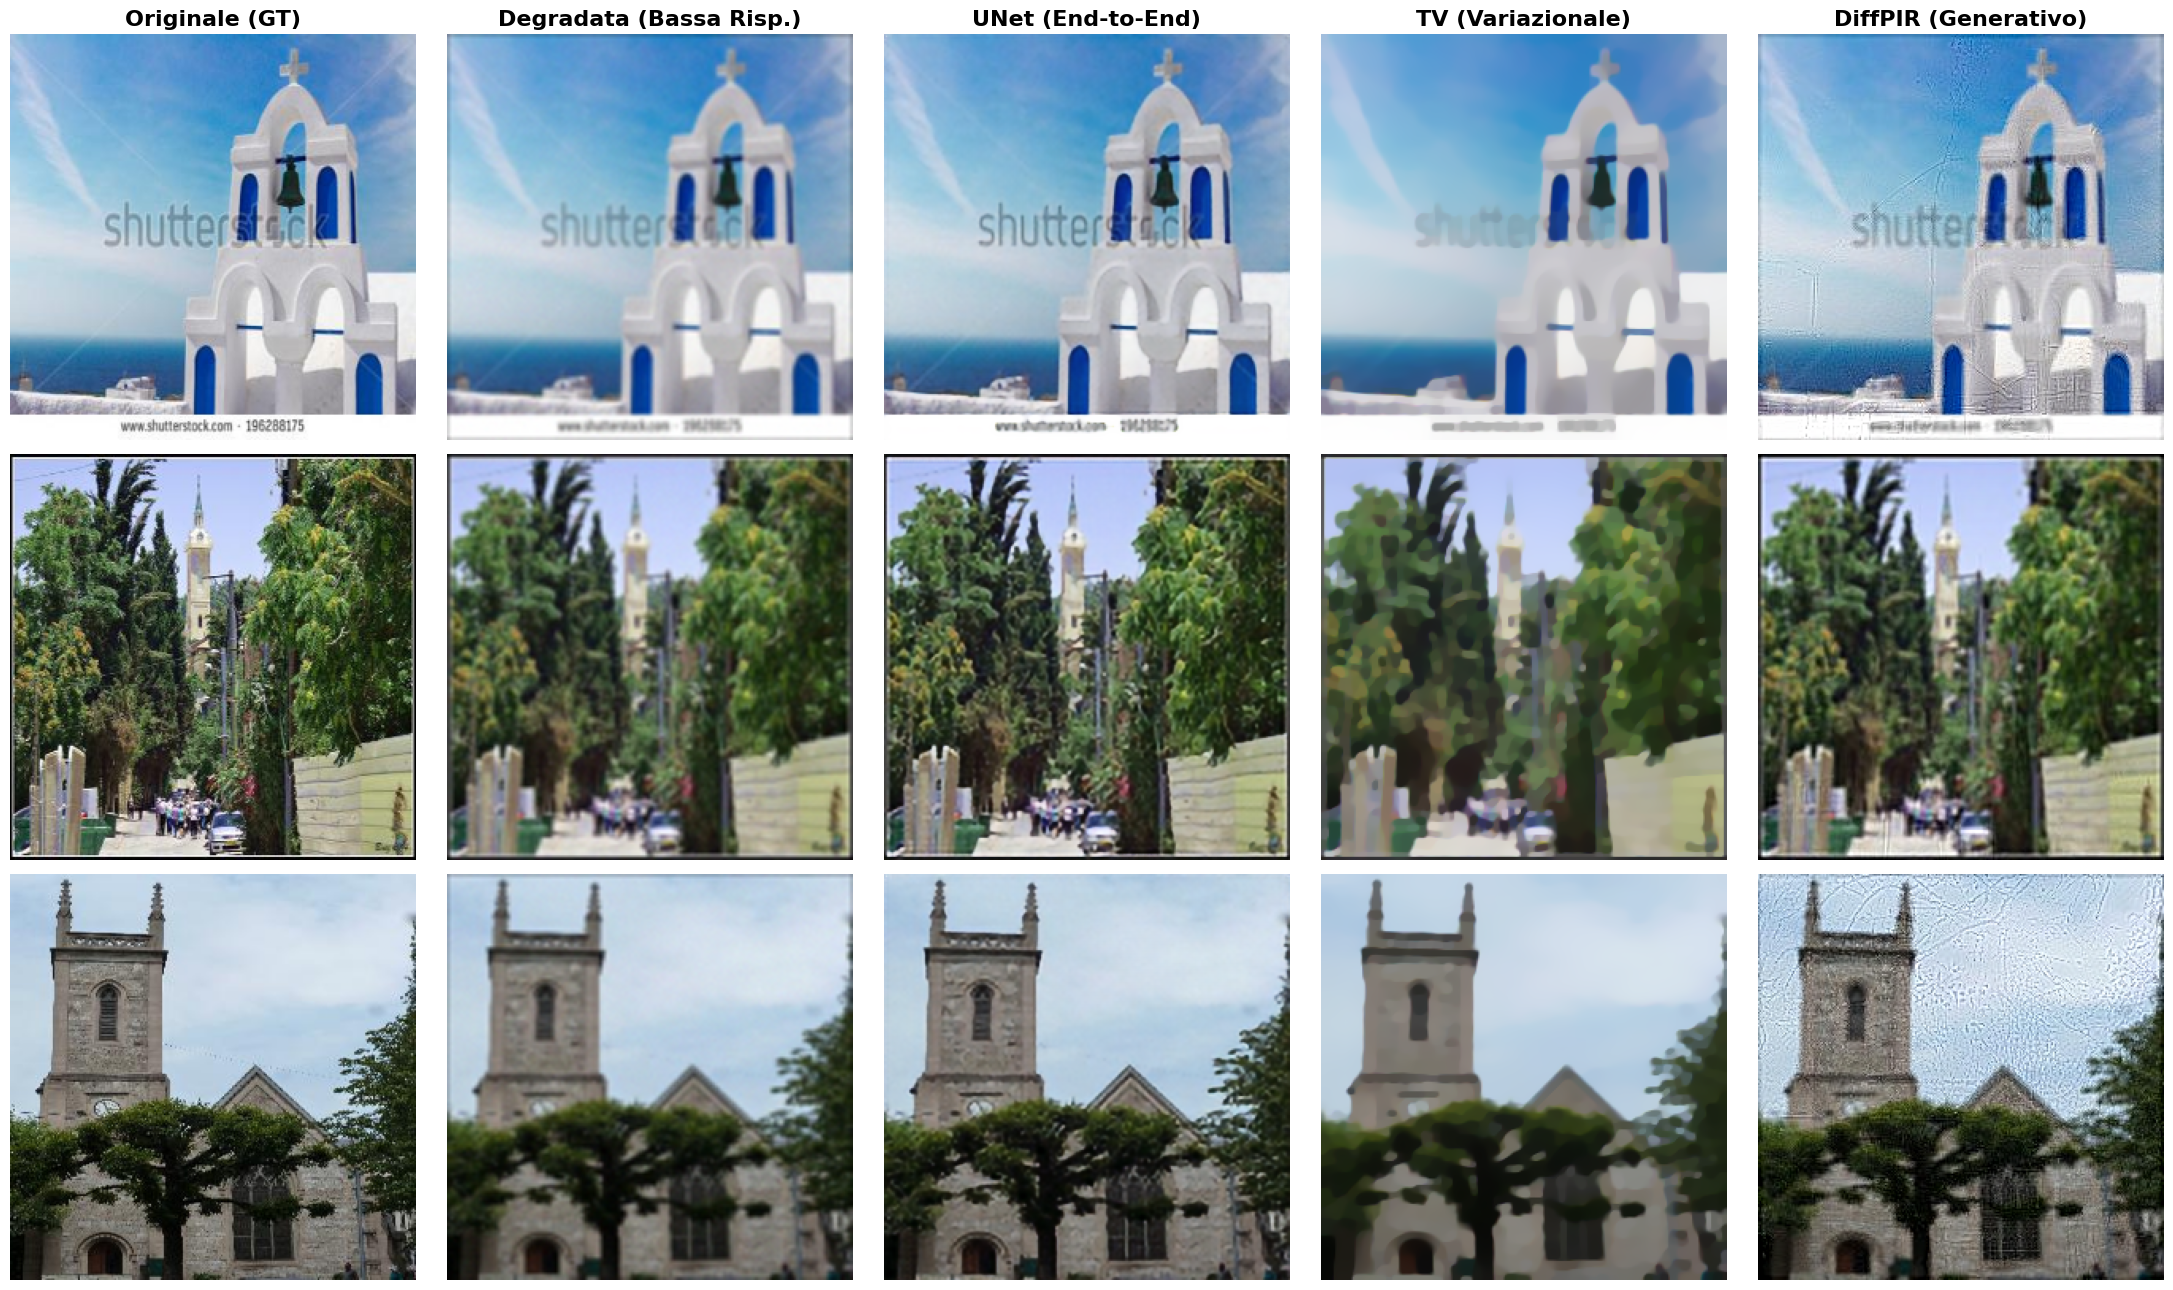

In [118]:
import matplotlib.pyplot as plt
import numpy as np
import torch

print("Inizializzazione Solutori in corso...")

# 1. Carica il Test Set
test_dataset = SRDataset(f"{KAGGLE_DATASET_PATH}/test", sr_factor=SR_FACTOR, noise_std=NOISE_STD)

# 2. Ricarica la UNet
unet_model.load_state_dict(torch.load('unet_best.pth'))
unet_model.eval()

# 3. Prepara i solutori TV e DiffPIR
tv_solver = TVSuperResolution(lambda_tv=0.05, n_iter=100, device=device)
diffpir_solver = DiffPIR(device=device)

# Ricreiamo il degrader per ottenere la VERA immagine a bassa risoluzione per TV e DiffPIR
degrader = DegradationOperator(sr_factor=SR_FACTOR, noise_std=NOISE_STD, device=device)

# --- VALUTAZIONE VISIVA SU 3 IMMAGINI ---
print("\nGenerazione del Plot Comparativo...")
fig, axes = plt.subplots(3, 5, figsize=(22, 13))
col_titles = ['Originale (GT)', 'Degradata (Bassa Risp.)', 'UNet (End-to-End)', 'TV (Variazionale)', 'DiffPIR (Generativo)']

for ax, title in zip(axes[0], col_titles):
    ax.set_title(title, fontsize=16, fontweight='bold')

for i in range(3):
    print(f"Ricostruzione Immagine {i+1}/3 in corso...")
    
    # degraded_up è 256x256 (per la UNet)
    # gt è l'originale 256x256
    degraded_up, gt = test_dataset[i]
    
    # Otteniamo la vera immagine degraded_lr a 128x128 per TV e DiffPIR
    degrader.seed = 42 + i  # Stesso seed = stesso rumore esatto!
    degraded_lr = degrader(gt.to(device))
    
    # 1. Ricostruzione UNet (prende input 256x256)
    with torch.no_grad():
        unet_out = unet_model(degraded_up.unsqueeze(0).to(device)).squeeze(0).cpu()
    
    # 2. Ricostruzione TV (prende input 128x128)
    tv_out = tv_solver.solve(degraded_lr).cpu()
    
    # 3. Ricostruzione DiffPIR (prende input 128x128)
    diff_out = diffpir_solver.restore(degraded_lr).cpu()
    
    # Stampa i risultati nella griglia
    imgs = [gt, degraded_up, unet_out, tv_out, diff_out]
    for j, img in enumerate(imgs):
        img_np = img.permute(1, 2, 0).numpy()
        img_np = np.clip(img_np, 0, 1)
        axes[i, j].imshow(img_np)
        axes[i, j].axis('off')

plt.tight_layout()
plt.show()
